<a href="https://colab.research.google.com/github/amrythem/Cognitive-Assignments/blob/main/Assignment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...


Cleaned Text:
 artificial intelligence is one of the most exciting technologies
in the modern world it enables machines to perform tasks that normally
require human intelligence ai is used in healthcare education
transportation and many other industries machine learning and deep
learning help computers learn from data and make predictions
chatbots and virtual assistants are popular examples of artificial
intelligence i believe ai will play an important role in shaping
the future of technology

Word Tokens:
 ['artificial', 'intelligence', 'is', 'one', 'of', 'the', 'most', 'exciting', 'technologies', 'in', 'the', 'modern', 'world', 'it', 'enables', 'machines', 'to', 'perform', 'tasks', 'that', 'normally', 'require', 'human', 'intelligence', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transportation', 'and', 'many', 'other', 'industries', 'machine', 'learning', 'and', 'deep', 'learning', 'help', 'computers', 'learn', 'from', 'data', 'and', 'make', 'predictions', 'chatbots', 'and

[nltk_data]   Unzipping corpora/stopwords.zip.


<Axes: title={'center': 'Top 10 Most Frequent Words'}, xlabel='Samples', ylabel='Counts'>

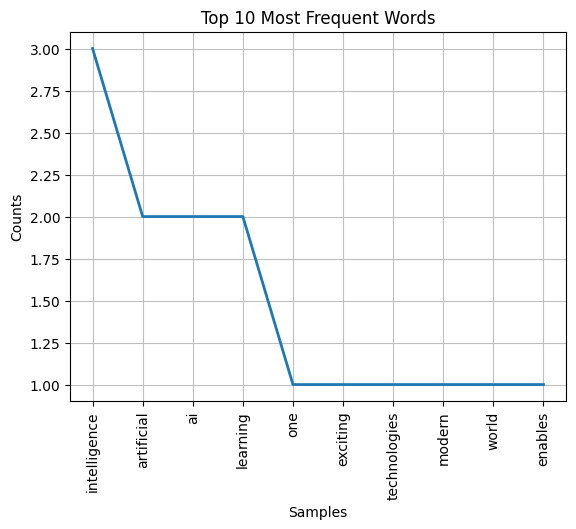

In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial Intelligence is one of the most exciting technologies
in the modern world. It enables machines to perform tasks that normally
require human intelligence. AI is used in healthcare, education,
transportation, and many other industries. Machine learning and deep
learning help computers learn from data and make predictions.
Chatbots and virtual assistants are popular examples of artificial
intelligence. I believe AI will play an important role in shaping
the future of technology."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(clean_text))

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nAfter Removing Stopwords:\n", filtered_words)

freq = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in freq.most_common():
    print(word, ":", count)

freq.plot(10, title="Top 10 Most Frequent Words")

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial Intelligence is one of the most exciting technologies
in the modern world. It enables machines to perform tasks that normally
require human intelligence. AI is used in healthcare, education,
transportation, and many other industries. Machine learning and deep
learning help computers learn from data and make predictions.
Chatbots and virtual assistants are popular examples of artificial
intelligence. I believe AI will play an important role in shaping
the future of technology."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Extracted Words:\n", words)

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nAfter Removing Stopwords:\n", filtered_words)

ps = PorterStemmer()
stemmed_words = [ps.stem(word) for word in filtered_words]

print("\nStemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:\n", lemmatized_words)

print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Extracted Words:
 ['artificial', 'intelligence', 'is', 'one', 'of', 'the', 'most', 'exciting', 'technologies', 'in', 'the', 'modern', 'world', 'it', 'enables', 'machines', 'to', 'perform', 'tasks', 'that', 'normally', 'require', 'human', 'intelligence', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transportation', 'and', 'many', 'other', 'industries', 'machine', 'learning', 'and', 'deep', 'learning', 'help', 'computers', 'learn', 'from', 'data', 'and', 'make', 'predictions', 'chatbots', 'and', 'virtual', 'assistants', 'are', 'popular', 'examples', 'of', 'artificial', 'intelligence', 'i', 'believe', 'ai', 'will', 'play', 'an', 'important', 'role', 'in', 'shaping', 'the', 'future', 'of', 'technology']

After Removing Stopwords:
 ['artificial', 'intelligence', 'one', 'exciting', 'technologies', 'modern', 'world', 'enables', 'machines', 'perform', 'tasks', 'normally', 'require', 'human', 'intelligence', 'ai', 'used', 'healthcare', 'education', 'transportation', 'many', 'industries

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial Intelligence is transforming the world. AI helps machines learn and make smart decisions.",
    "Machine Learning is a branch of AI. It allows computers to learn from data and improve performance.",
    "Blockchain technology provides secure transactions. It is used in cryptocurrency and digital banking."
]

cv = CountVectorizer()
bow_matrix = cv.fit_transform(texts)

print("BAG OF WORDS REPRESENTATION:")
print("Feature Names:", cv.get_feature_names_out())
print(bow_matrix.toarray())

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)

print("\nTF-IDF REPRESENTATION:")
print(tfidf_matrix.toarray())

feature_names = tfidf.get_feature_names_out()

print("\nTOP 3 KEYWORDS FROM EACH TEXT:")

for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]

    print(f"\nText {i+1}:")
    for index in top_indices:
        print(feature_names[index], ":", round(row[index], 3))

BAG OF WORDS REPRESENTATION:
Feature Names: ['ai' 'allows' 'and' 'artificial' 'banking' 'blockchain' 'branch'
 'computers' 'cryptocurrency' 'data' 'decisions' 'digital' 'from' 'helps'
 'improve' 'in' 'intelligence' 'is' 'it' 'learn' 'learning' 'machine'
 'machines' 'make' 'of' 'performance' 'provides' 'secure' 'smart'
 'technology' 'the' 'to' 'transactions' 'transforming' 'used' 'world']
[[1 0 1 1 0 0 0 0 0 0 1 0 0 1 0 0 1 1 0 1 0 0 1 1 0 0 0 0 1 0 1 0 0 1 0 1]
 [1 1 1 0 0 0 1 1 0 1 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 0]
 [0 0 1 0 1 1 0 0 1 0 0 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0 0 1 0 1 0]]

TF-IDF REPRESENTATION:
[[0.22088853 0.         0.17153965 0.29044187 0.         0.
  0.         0.         0.         0.         0.29044187 0.
  0.         0.29044187 0.         0.         0.29044187 0.17153965
  0.         0.22088853 0.         0.         0.29044187 0.29044187
  0.         0.         0.         0.         0.29044187 0.
  0.29044187 0.         0.         0.290441

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial Intelligence enables machines to perform tasks
that require human intelligence. It uses machine learning and deep
learning algorithms. AI helps computers analyze data and make
predictions. It is widely used in healthcare, education, and robotics."""

text2 = """Blockchain is a decentralized digital ledger technology.
It stores information securely in blocks. Blockchain is used in
cryptocurrency, banking, and digital transactions. It provides
transparency, security, and trust."""

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    return text

clean_text1 = preprocess(text1)
clean_text2 = preprocess(text2)

print("Preprocessed Text 1:\n", clean_text1)
print("\nPreprocessed Text 2:\n", clean_text2)

words1 = clean_text1.split()
words2 = clean_text2.split()

print("\nTokens of Text 1:", words1)
print("\nTokens of Text 2:", words2)

set1 = set(words1)
set2 = set(words2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

documents = [clean_text1, clean_text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

cosine = cosine_similarity(tfidf_matrix[0:1],
                           tfidf_matrix[1:2])

print("Cosine Similarity:", round(cosine[0][0], 4))
print("\nSimilarity Analysis:")
print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine[0][0], 4))

Preprocessed Text 1:
 artificial intelligence enables machines to perform tasks
that require human intelligence it uses machine learning and deep
learning algorithms ai helps computers analyze data and make
predictions it is widely used in healthcare education and robotics

Preprocessed Text 2:
 blockchain is a decentralized digital ledger technology
it stores information securely in blocks blockchain is used in
cryptocurrency banking and digital transactions it provides
transparency security and trust

Tokens of Text 1: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'perform', 'tasks', 'that', 'require', 'human', 'intelligence', 'it', 'uses', 'machine', 'learning', 'and', 'deep', 'learning', 'algorithms', 'ai', 'helps', 'computers', 'analyze', 'data', 'and', 'make', 'predictions', 'it', 'is', 'widely', 'used', 'in', 'healthcare', 'education', 'and', 'robotics']

Tokens of Text 2: ['blockchain', 'is', 'a', 'decentralized', 'digital', 'ledger', 'technology', 'it', 'stores',

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


SENTIMENT ANALYSIS RESULTS:

Review 1 : The smartphone has an excellent camera and amazing battery life. The performance is very smooth. I really love this product.
Polarity: 0.66
Sentiment: Positive

Review 2 : The phone is very slow and the battery drains quickly. The camera quality is poor. I am disappointed with this purchase.
Polarity: -0.3
Sentiment: Negative

Review 3 : The smartphone has a good display and average battery life. It works fine for daily use.
Polarity: 0.24
Sentiment: Positive



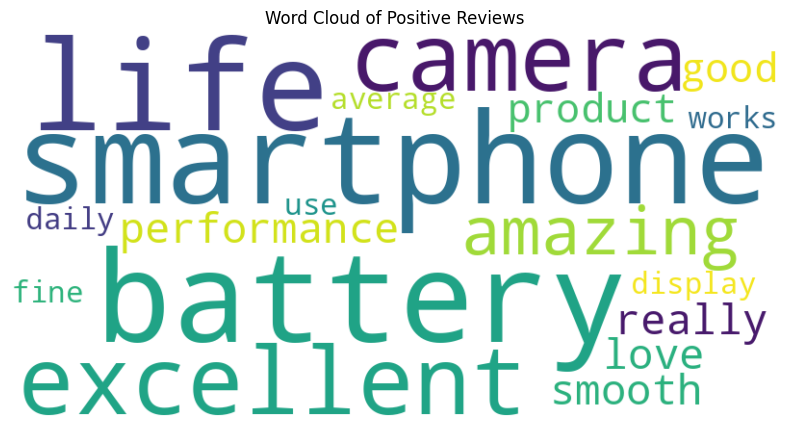

In [5]:
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

nltk.download('punkt')

reviews = [
    "The smartphone has an excellent camera and amazing battery life. The performance is very smooth. I really love this product.",

    "The phone is very slow and the battery drains quickly. The camera quality is poor. I am disappointed with this purchase.",

    "The smartphone has a good display and average battery life. It works fine for daily use."
]

positive_reviews = []
print("SENTIMENT ANALYSIS RESULTS:\n")

for i, review in enumerate(reviews):
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)

    elif polarity < 0:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    print("Review", i + 1, ":", review)
    print("Polarity:", round(polarity, 2))
    print("Sentiment:", sentiment)
    print()

text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()

In [6]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial Intelligence is changing the world of technology.
It allows computers to perform tasks that normally require human
intelligence. Machine learning is an important part of artificial
intelligence. It helps machines learn from data and improve their
performance. Deep learning uses neural networks to solve complex
problems. AI is used in healthcare, education, banking, and
transportation. Chatbots help users by answering their questions.
Self driving cars use AI to understand their surroundings.
In the future, artificial intelligence will make technology
smarter and more efficient. It will create new opportunities
and transform the way people work and communicate."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total Words:", total_words)

input_sequences = []

for line in text.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max(len(x) for x in input_sequences)

input_sequences = np.array(
    pad_sequences(
        input_sequences,
        maxlen=max_sequence_len,
        padding='pre'
    )
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = np.eye(total_words)[y]

model = Sequential()

model.add(Embedding(total_words, 50))
model.add(LSTM(100))
model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=1)

print("\nModel Training Completed!")

def generate_text(seed_text, next_words):
    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences(
            [seed_text]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len-1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)

        predicted_word_index = np.argmax(predicted, axis=-1)[0]

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if output_word == "":
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print(generate_text("artificial", 15))
print(generate_text("machine", 15))
print(generate_text("technology", 15))

Total Words: 73
Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.0115 - loss: 4.2899  
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0690 - loss: 4.2809
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0805 - loss: 4.2713
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0805 - loss: 4.2597
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0690 - loss: 4.2409
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0575 - loss: 4.2102    
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0460 - loss: 4.1632
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0345 - loss: 4.1278
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.0345 - loss: 4.1087
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0345 - loss: 4.0882
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0805 - loss: 4.0622
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step -